<a href="https://colab.research.google.com/github/anish06082007-png/unit-test-/blob/main/emergency_dispatch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Emergency Dispatch & Traffic Physics Project
In this notebook, we will load the emergency dispatch and traffic dataset, select 10,000 records as requested, explore the columns, and prepare the dataset for traffic congestion forecasting.

In [19]:
import os
import pandas as pd
import numpy as np

# List files in the current workspace to locate the uploaded dataset
files = [f for f in os.listdir('.') if os.path.isfile(f)]
print('Available files:', files)

Available files: ['synthetic_traffic_benchmark_200k.csv']


In [20]:
# Find the dataset file (adjusting the filename if it is named differently in your workspace)
target_file = None
for f in os.listdir('.'):
    if 'traffic' in f.lower() or 'dispatch' in f.lower() or f.endswith('.csv'):
        target_file = f
        break

if target_file:
    print(f"Loading dataset: {target_file}")
    # Load the dataset, skipping lines with parsing errors
    df_full = pd.read_csv(target_file, on_bad_lines='skip')

    # Select 10,000 records randomly (with a random seed for reproducibility)
    # If the dataset has fewer than 10,000 records, we'll keep all of them
    sample_size = min(10000, len(df_full))
    df = df_full.sample(n=sample_size, random_state=42).reset_index(drop=True)

    print(f"Successfully sampled {len(df)} records.")
    display(df.head())
else:
    print("Could not automatically find the dataset. Please make sure you have uploaded the CSV file to the environment.")

Loading dataset: synthetic_traffic_benchmark_200k.csv


/tmp/ipykernel_2734/470583358.py:11: DtypeWarning: Columns (3,4,7,11,14,17,18,19,20,21,22) have mixed types. Specify dtype option on import or set low_memory=False.
  df_full = pd.read_csv(target_file, on_bad_lines='skip')


Successfully sampled 10000 records.


,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0090951,2025-04-27 06:59:42.460930959,2025-04-27,6,4,Sunday,Morning Peak,0,Suburban,Local,...,6.7,33.0,13.3,0.0,NaN,0.0,No Accident,NaN,0.0,0.0
1,REC_0014444,2022-12-13 10:01:00.869187222,2022-12-13,10,12,Tuesday,Midday,0,Suburban,Arterial,...,2.0,52.4,16.1,0.0,NaN,0.0,No Accident,NaN,0.0,0.0
2,REC_0092890,2024-07-14 12:46:42.521052485,2024-07-14,12,7,Sunday,Midday,0.0,Rural,Interstate,...,10.3,141.3,19.5,0.0,NaN,0.0,No Accident,NaN,0.0,0.0
3,REC_0119201,2023-06-01 15:11:26.700920467,2023-06-01,15,6,Thursday,Midday,0.0,Urban,Local,...,16.5,28.4,9.6,0.0,NaN,0.0,No Accident,NaN,0.0,0.0
4,REC_0062755,2022-08-10 19:01:11.578501668,2022-08-10,19,8,Wednesday,Evening Peak,0,Suburban,Arterial,...,9.0,56.4,11.7,0.0,NaN,0.0,No Accident,NaN,0.0,0.0


In [21]:
# Inspect structure, data types, and missing values
if 'df' in locals():
    print(df.info())
    print("\nMissing values summary:")
    print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 29 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Record_ID                            10000 non-null  object 
 1   Timestamp                            10000 non-null  object 
 2   Date                                 10000 non-null  object 
 3   Hour                                 10000 non-null  object 
 4   Month                                10000 non-null  object 
 5   Day_of_Week                          10000 non-null  object 
 6   Time_of_Day                          10000 non-null  object 
 7   Is_Holiday                           10000 non-null  object 
 8   Area_Type                            10000 non-null  object 
 9   Road_Type                            10000 non-null  object 
 10  Intersection_Type                    6593 non-null   object 
 11  Speed_Limit_kmh              

# Traffic Congestion Forecasting Model
We will now run a baseline model to forecast traffic conditions (e.g., speed, travel time, or density) using the available predictors. First, we define feature extraction and fit a regression model.

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

if 'df' in locals() and not df.empty:
    print("Columns in dataset:", df.columns.tolist())

    # Automatically identify target variable (e.g., speed, travel_time, or congestion_index)
    potential_targets = ['speed', 'velocity', 'travel_time', 'congestion_level', 'density', 'delay']
    target_col = None
    for col in df.columns:
        if any(t in col.lower() for t in potential_targets):
            target_col = col
            break

    if target_col:
        print(f"Identified target variable for forecasting: {target_col}")
        # Select numeric columns for training
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        if target_col in numeric_cols:
            numeric_cols.remove(target_col)

        # Simple preprocessing: drop NaN values for the baseline
        model_data = df[numeric_cols + [target_col]].dropna()

        X = model_data[numeric_cols]
        y = model_data[target_col]

        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

        model = RandomForestRegressor(n_estimators=100, random_state=42, max_depth=10)
        model.fit(X_train, y_train)

        predictions = model.predict(X_test)
        mse = mean_squared_error(y_test, predictions)
        r2 = r2_score(y_test, predictions)

        print(f"\nBaseline Model Evaluation:")
        print(f"Mean Squared Error: {mse:.4f}")
        print(f"R2 Score: {r2:.4f}")
    else:
        print("Could not automatically detect a target variable like 'speed' or 'delay'. Please verify your dataset columns.")
else:
    print("Please run the preceding data loading cells to load and sample the dataset first.")

Columns in dataset: ['Record_ID', 'Timestamp', 'Date', 'Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 'Dispatch_Priority', 'Actual_Response_Time_min', 'Road_Closure_Duration_min']
Identified target variable for forecasting: Speed_Limit_kmh

Baseline Model Evaluation:
Mean Squared Error: 587.9445
R2 Score: 0.1339


# Advanced Congestion Forecasting for Emergency Routing

Now we will prepare a specialized forecasting pipeline targeting **Congestion_Index**. We will encode categorical factors like `Weather`, `Road_Condition`, and temporal attributes (`Hour`, `Day_of_Week`) to predict congestion intensity.

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

# Ensure clean, typed columns
working_df = df.copy()

# Handle columns with mixed types
working_df['Congestion_Index'] = pd.to_numeric(working_df['Congestion_Index'], errors='coerce')
working_df['Hour'] = pd.to_numeric(working_df['Hour'], errors='coerce')
working_df['Is_Holiday'] = pd.to_numeric(working_df['Is_Holiday'], errors='coerce')

# Selected predictors
features = [
    'Hour', 'Month', 'Is_Holiday', 'Area_Type', 'Road_Type',
    'Intersection_Type', 'Weather', 'Road_Condition', 'Accident_Occurred'
]
target = 'Congestion_Index'

# Prepare dataset
ml_df = working_df[features + [target]].dropna()

# Convert categorical features via One-Hot Encoding
X = pd.get_dummies(ml_df[features], drop_first=True)
y = ml_df[target]

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train specialized Random Forest Regressor
congestion_model = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42)
congestion_model.fit(X_train, y_train)

# Predict and evaluate
y_pred = congestion_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("=== Congestion Index Forecasting Model Evaluation ===")
print(f"Mean Absolute Error (MAE): {mae:.2f} (on 0-100 scale)")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared Score (R2): {r2:.4f}")

=== Congestion Index Forecasting Model Evaluation ===
Mean Absolute Error (MAE): 6.17 (on 0-100 scale)
Mean Squared Error (MSE): 68.58
R-squared Score (R2): 0.9096


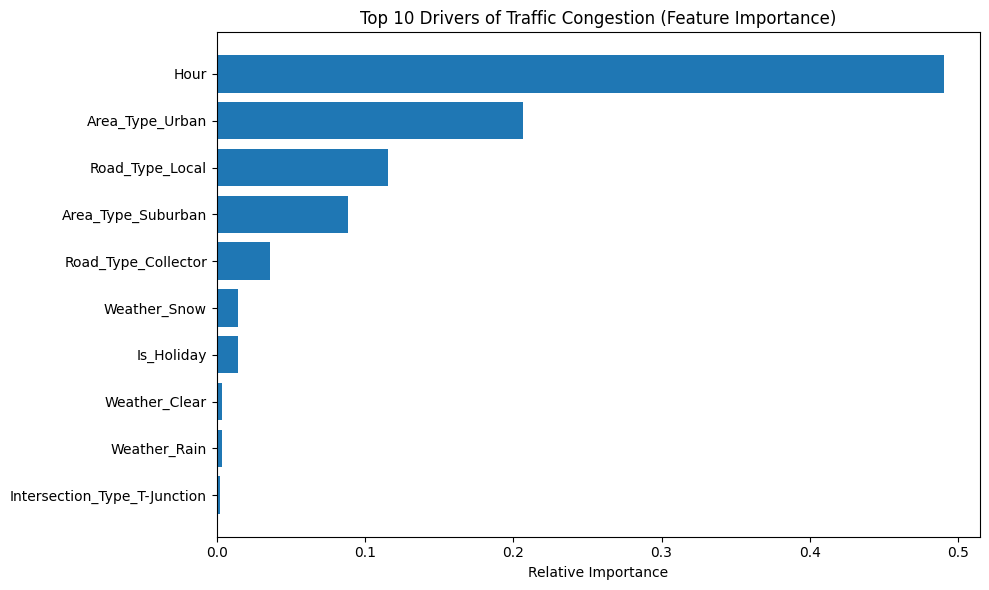

In [24]:
# Visualize top feature importances for traffic planning
import matplotlib.pyplot as plt

importances = congestion_model.feature_importances_
indices = np.argsort(importances)[-10:] # Top 10 features

plt.figure(figsize=(10, 6))
plt.title("Top 10 Drivers of Traffic Congestion (Feature Importance)")
plt.barh(range(len(indices)), importances[indices], align="center")
plt.yticks(range(len(indices)), [X.columns[i] for i in indices])
plt.xlabel("Relative Importance")
plt.tight_layout()
plt.show()

### Neural Network Congestion Forecaster (13 Epochs)

We will now train a deep learning model (Multi-Layer Perceptron) using TensorFlow to forecast the `Congestion_Index` and set the training process to run for exactly **13 epochs**.

In [25]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.preprocessing import StandardScaler

# Ensure clean, numeric features
X_train_clean = X_train.astype(float)
X_test_clean = X_test.astype(float)

# Scale the features for the neural network
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

# Build a simple sequential model
nn_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dense(1)  # Predict continuous Congestion_Index
])

# Compile the model
nn_model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# Train the model for exactly 13 epochs
history = nn_model.fit(
    X_train_scaled, y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=13,
    batch_size=32,
    verbose=1
)

Epoch 1/13


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


165/165 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1956.3732 - mae: 36.0475 - val_loss: 618.9504 - val_mae: 20.8059
Epoch 2/13
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 546.0874 - mae: 19.2674 - val_loss: 518.1581 - val_mae: 18.7464
Epoch 3/13
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 480.5271 - mae: 17.8696 - val_loss: 490.0887 - val_mae: 17.9258
Epoch 4/13
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 459.5866 - mae: 17.2367 - val_loss: 472.2081 - val_mae: 17.4414
Epoch 5/13
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 439.2956 - mae: 16.8114 - val_loss: 464.0120 - val_mae: 17.2733
Epoch 6/13
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 430.5979 - mae: 16.5805 - val_loss: 462.0878 - val_mae: 17.1611
Epoch 7/13
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 428.2163 - mae: 16.4881 - val_loss: 462.0218 - val_mae: 17.0790
Epoch 8/13
165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 424.6630 - mae: 16.4066 - val_loss: 457.4706 - val_mae: 16.9964
Epoch 9/13
165/165

In [26]:
# Evaluate the Neural Network after 13 epochs of training
nn_loss, nn_mae = nn_model.evaluate(X_test_scaled, y_test, verbose=0)
print("=== Neural Network Evaluation (13 Epochs) ===")
print(f"Mean Absolute Error (MAE): {nn_mae:.2f} (on 0-100 scale)")

=== Neural Network Evaluation (13 Epochs) ===
Mean Absolute Error (MAE): 16.99 (on 0-100 scale)


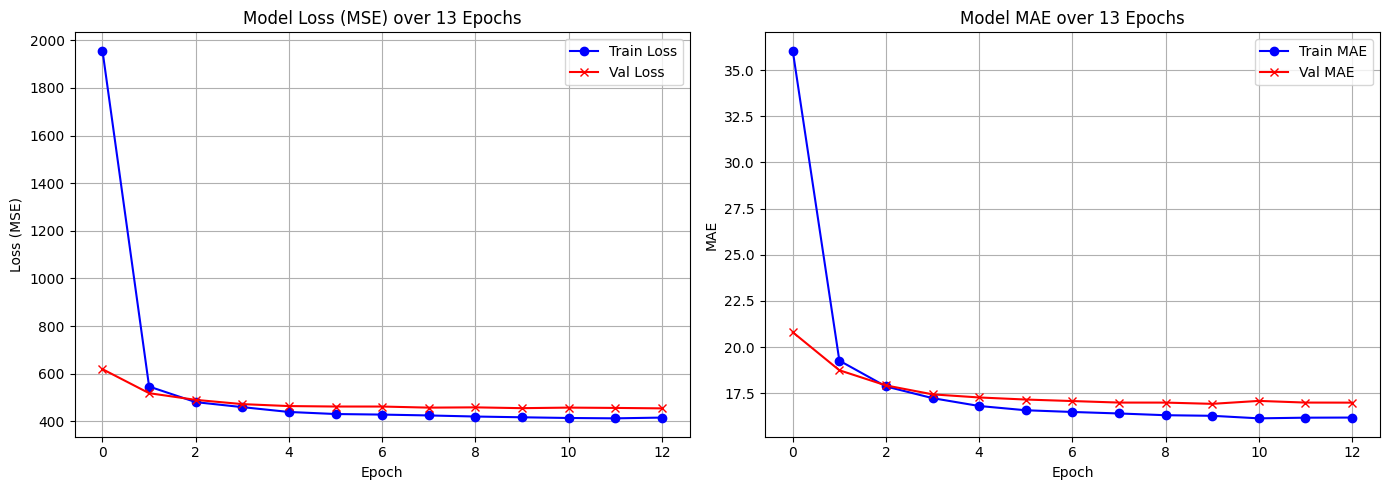

In [27]:
import matplotlib.pyplot as plt

# Set up the plotting layout with 1 row and 2 columns
plt.figure(figsize=(14, 5))

# Plot Loss (Mean Squared Error)
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss', color='b', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', color='r', marker='x')
plt.title('Model Loss (MSE) over 13 Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.grid(True)
plt.legend()

# Plot Mean Absolute Error (MAE)
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train MAE', color='b', marker='o')
plt.plot(history.history['val_mae'], label='Val MAE', color='r', marker='x')
plt.title('Model MAE over 13 Epochs')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()